In [7]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch import nn
import torch
from PIL import Image


In [4]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.testingStack = nn.Sequential(
            # 3x3 x 3 x 32 + 32
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),

            # 3x3 x 32 x 32 + 32
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # 3x3 x 32 x 64 + 64
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 3x3 x 64x 128 + 128
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),

            # 128 x 10 + 10
            nn.Linear(128,10)
        )

    def forward(self,x):
        logits = self.testingStack(x)
        return logits
    
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
net = NeuralNetwork().to(device)

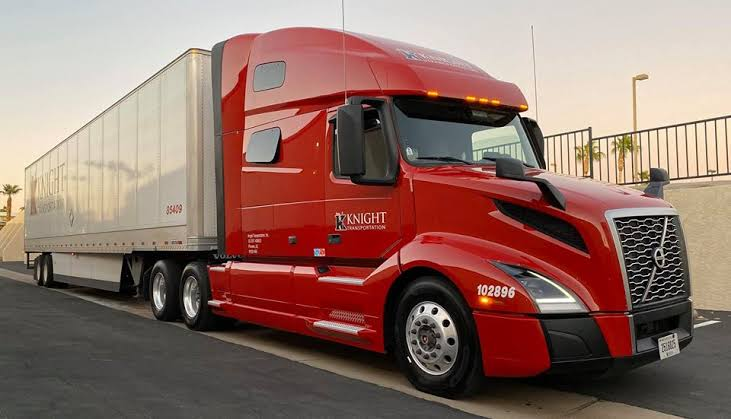

Predicted: truck


In [25]:
model = NeuralNetwork().to(device)
model.load_state_dict(torch.load("/Users/tykea/Developer/deep-learning/models/cifar-10.pth",weights_only=True))

classes =['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

eval_transform = transforms.ToTensor()

with Image.open('/Users/tykea/Desktop/images.jpeg') as img:
    photo = img.convert("RGB")

display(photo)

photo = transforms.Resize((32, 32))(photo)
x = eval_transform(photo).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    logits = model(x)
    predicted_idx = logits.argmax(dim=1).item()

print("Predicted:", classes[predicted_idx])